<a href="https://colab.research.google.com/github/sen-soumya/Optical-communication/blob/main/Optical%20Link%20optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Imports and Environment Setup

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import random
import matplotlib.pyplot as plt
from collections import deque

class GreenOpticalLinkEnv:
    def __init__(self):
        self.state_dim = 3
        self.action_dim = 5
        self.reset()

    def reset(self):
        self.temperature = 298.5
        self.phase_error = 0.01
        self.snr = 22.0
        return np.array([self.snr, self.phase_error, self.temperature], dtype=np.float32)

    def step(self, action):
        I_bias  = float(np.clip(action[0] * 90.0 + 10.0, 10.0, 100.0))
        V_mod   = float(np.clip(action[1] * 2.4 + 0.1, 0.1, 2.5))
        P_tx    = float(np.clip(action[2] * 15.0 - 5.0, -5.0, 10.0))
        B_ghz   = float(np.clip(action[3] * 90.0 + 10.0, 10.0, 100.0))
        alpha_p = float(np.clip(action[4] * 0.99 + 0.01, 0.01, 1.0))

        P_tx_linear = 10**(P_tx / 10.0)

        electrical_power_watts = (I_bias * 1e-3 * 1.2) + (V_mod**2 / 50.0)
        achievable_bitrate_gbps = B_ghz * np.log2(1.0 + (P_tx_linear / (0.01 * B_ghz)))
        joules_per_bit = electrical_power_watts / (achievable_bitrate_gbps * 1e9)

        laser_chirp = 3.5 * (V_mod / (I_bias + 1.0))
        self.temperature += 0.1 * electrical_power_watts - 0.02 * (self.temperature - 298.5)
        thermal_drift_penalty = 0.05 * (self.temperature - 298.5)**2
        kerr_nonlinearity = 0.8 * (P_tx_linear**2) * (1.0 / (alpha_p + 0.1))

        total_distortion = laser_chirp + kerr_nonlinearity + thermal_drift_penalty + 1e-6
        self.snr = 35.0 - 10.0 * np.log10(total_distortion) - (0.05 * B_ghz)
        self.snr = max(1.0, self.snr)

        spectral_efficiency = np.log2(1.0 + 10**(self.snr / 10.0))
        reward = spectral_efficiency / (joules_per_bit * 1e8)

        if self.snr < 7.0:
            reward -= 50.0

        self.phase_error = 0.9 * self.phase_error + 0.1 * laser_chirp
        next_state = np.array([self.snr, self.phase_error, self.temperature], dtype=np.float32)

        return next_state, reward, joules_per_bit, spectral_efficiency

### 2. DDPG Actor-Critic Networks

In [2]:
class ActorNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, action_dim),
            nn.Sigmoid()
        )
    def forward(self, state):
        return self.net(state)

class CriticNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super().__init__()
        self.state_fc = nn.Linear(state_dim, 64)
        self.action_fc = nn.Linear(action_dim, 64)
        self.joint_fc = nn.Sequential(
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )
    def forward(self, state, action):
        s_out = torch.relu(self.state_fc(state))
        a_out = torch.relu(self.action_fc(action))
        return self.joint_fc(torch.cat([s_out, a_out], dim=1))

### 3. Agent Training Loop

In [9]:
env = GreenOpticalLinkEnv()

actor = ActorNetwork(env.state_dim, env.action_dim)
critic = CriticNetwork(env.state_dim, env.action_dim)

actor_opt = optim.Adam(actor.parameters(), lr=0.001)
critic_opt = optim.Adam(critic.parameters(), lr=0.002)
memory_buffer = deque(maxlen=5000)

steps = 800
batch_size = 64
state = env.reset()

history_rewards = []
history_j_per_bit = []
history_spectral_eff = []

print("Starting agent training...")

for step in range(1, steps + 1):
    state_t = torch.FloatTensor(state).unsqueeze(0)
    with torch.no_grad():
        raw_action = actor(state_t).squeeze(0).numpy()

    noise = np.random.normal(0, 0.15 / (1.0 + step * 0.002), size=env.action_dim)
    action = np.clip(raw_action + noise, 0.0, 1.0)

    next_state, reward, j_per_bit, spec_eff = env.step(action)
    memory_buffer.append((state, action, reward, next_state))

    if len(memory_buffer) > batch_size:
        batch = random.sample(memory_buffer, batch_size)
        b_states, b_actions, b_rewards, b_next_states = zip(*batch)

        b_states = torch.FloatTensor(np.array(b_states))
        b_actions = torch.FloatTensor(np.array(b_actions))
        b_rewards = torch.FloatTensor(b_rewards).unsqueeze(1)
        b_next_states = torch.FloatTensor(np.array(b_next_states))

        with torch.no_grad():
            next_q = critic(b_next_states, actor(b_next_states))
            target_q = b_rewards + 0.95 * next_q
        current_q = critic(b_states, b_actions)
        critic_loss = nn.MSELoss()(current_q, target_q)

        critic_opt.zero_grad()
        critic_loss.backward()
        critic_opt.step()

        actor_loss = -critic(b_states, actor(b_states)).mean()
        actor_opt.zero_grad()
        actor_loss.backward()
        actor_opt.step()

    state = next_state
    history_rewards.append(reward)
    history_j_per_bit.append(j_per_bit)
    history_spectral_eff.append(spec_eff)

    if step % 200 == 0:
        print(f"Step {step}/{steps} | Reward: {np.mean(history_rewards[-20:]):.2f} | Energy: {j_per_bit*1e12:.3f} pJ/bit | Spectral Eff: {spec_eff:.2f} bits/s/Hz")

Starting agent training...
Step 200/800 | Reward: 19484.00 | Energy: 1.990 pJ/bit | Spectral Eff: 5.18 bits/s/Hz
Step 400/800 | Reward: 57951.03 | Energy: 0.697 pJ/bit | Spectral Eff: 4.00 bits/s/Hz
Step 600/800 | Reward: 57255.91 | Energy: 0.782 pJ/bit | Spectral Eff: 4.63 bits/s/Hz
Step 800/800 | Reward: 58089.42 | Energy: 0.682 pJ/bit | Spectral Eff: 3.76 bits/s/Hz


### 4. Performance Metrics Visualization

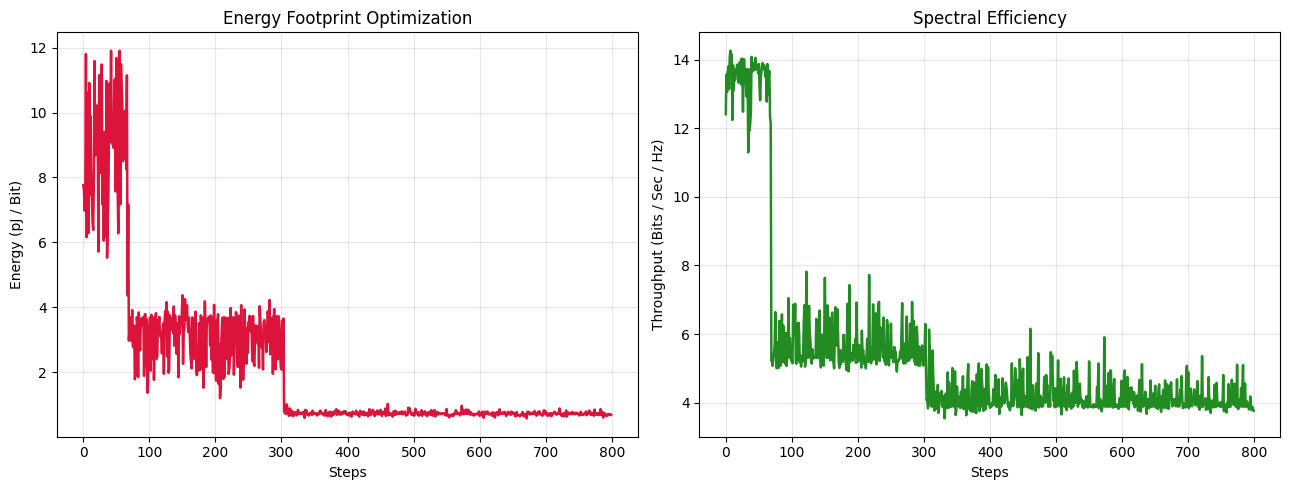

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(np.array(history_j_per_bit) * 1e12, color='crimson', lw=1.8)
ax1.set_title("Energy Footprint Optimization")
ax1.set_xlabel("Steps")
ax1.set_ylabel("Energy (pJ / Bit)")
ax1.grid(True, alpha=0.3)

ax2.plot(history_spectral_eff, color='forestgreen', lw=1.8)
ax2.set_title("Spectral Efficiency")
ax2.set_xlabel("Steps")
ax2.set_ylabel("Throughput (Bits / Sec / Hz)")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()